# HMM Market Regime

Minute-frequency market regime prediction with a Gaussian Hidden Markov Model.

This notebook consolidates the HMM (Markov) pipeline end to end: data preparation, market-state prediction, in-sample / out-of-sample backtesting, full-period evaluation, results export, and Combinatorial Purged Cross-Validation (CPCV).

# 1. Data Preparation

## 1.1 Data Inspection

In [3]:
#导包
import pandas as pd
import numpy as np
from hmmlearn import hmm
import joblib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import mode
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号

In [4]:
df_min = pd.read_csv('../data/kline_im.csv')
df_min.set_index('DateTime', inplace=True)
df_min

,Unnamed: 0,day,open,high,low,close,vol,amount,twap,rsrs,...,max_ret_index,min_ret_index,max_amount_index,increase_kline_ratio,decrease_kline_ratio,equal_kline_ratio,vwap_ema_1,vwap_ema_2,pct,slippage
DateTime,,,,,,,,,,,,,,,,,,,,,
2022/7/22 9:30,0,2022/7/22,5041.799985,5076.999985,5032.799985,5047.599985,2597,3670919280,5062.106651,0.514591,...,1,13,0,0.533333,0.400000,0.066667,1.411248e+06,1.413470e+06,-0.011966,1.981140e-07
2022/7/22 9:45,1,2022/7/22,5048.199985,5048.599985,4976.799985,4987.199985,2292,3214320560,5001.066651,0.973886,...,7,2,5,0.200000,0.800000,0.000000,1.399274e+06,1.402205e+06,0.003930,2.005133e-07
2022/7/22 10:00,2,2022/7/22,4987.199985,5016.199985,4984.399985,5006.799985,1422,1994239360,5004.039985,0.818966,...,0,13,13,0.666667,0.266667,0.066667,1.403338e+06,1.402740e+06,0.006551,1.997284e-07
2022/7/22 10:15,3,2022/7/22,5008.199985,5045.599985,5000.799985,5039.599985,1392,1957681760,5022.933318,1.042818,...,10,0,11,0.666667,0.333333,0.000000,1.408995e+06,1.406698e+06,-0.003730,1.984284e-07
2022/7/22 10:30,4,2022/7/22,5039.399985,5039.599985,5016.799985,5020.799985,1118,1572904440,5025.826651,1.083749,...,3,2,11,0.333333,0.666667,0.000000,1.406104e+06,1.406730e+06,-0.005577,1.991714e-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026/3/20 13:45,11,2026/3/20,7660.000000,7666.200000,7642.000000,7643.800000,5447,8336630920,7652.946667,1.085567,...,8,9,1,0.400000,0.600000,0.000000,1.529395e+06,1.530344e+06,-0.001465,1.308250e-07
2026/3/20 14:00,12,2026/3/20,7643.800000,7664.800000,7625.600000,7632.600000,6613,10109080200,7643.773333,1.033320,...,6,8,9,0.400000,0.533333,0.066667,1.526780e+06,1.528041e+06,-0.000524,1.310170e-07
2026/3/20 14:15,13,2026/3/20,7633.000000,7643.800000,7619.400000,7628.600000,5162,7878171720,7631.746667,0.822899,...,2,4,2,0.466667,0.533333,0.000000,1.525637e+06,1.526077e+06,-0.002779,1.310857e-07


## 1.2 Feature Engineering

Select 5 features.

In [5]:
# im_model
df_min['vol_log_ret_1p'] = np.log(df_min['vol']) - np.log(df_min['vol'].shift(1))

df_min['vol_log_ret_5p'] = np.log(df_min['vol']) - np.log(df_min['vol'].shift(5))

df_min['close_log_ret_1p'] = np.log(df_min['close']) - np.log(df_min['close'].shift(1))

df_min['close_log_ret_5p'] = np.log(df_min['close']) - np.log(df_min['close'].shift(5))

df_min['intraday_range_log'] = np.log(df_min['high']) - np.log(df_min['low'])
# 删除前五行数据（滑窗）
df_min = df_min.drop(df_min.index[:5])
df_min.index = pd.to_datetime(df_min.index)
df_min[:15]

,Unnamed: 0,day,open,high,low,close,vol,amount,twap,rsrs,...,equal_kline_ratio,vwap_ema_1,vwap_ema_2,pct,slippage,vol_log_ret_1p,vol_log_ret_5p,close_log_ret_1p,close_log_ret_5p,intraday_range_log
DateTime,,,,,,,,,,,,,,,,,,,,,
2022-07-22 10:45:00,5,2022/7/22,5021.399985,5021.399985,4990.999985,4992.799985,1019,1429435160,5005.079985,0.809127,...,0.000000,1.401266e+06,1.402722e+06,-0.000881,2.002884e-07,-0.092720,-0.935535,-0.005592,-0.010916,0.006072
2022-07-22 11:00:00,6,2022/7/22,4994.199985,5006.599985,4986.199985,4988.399985,778,1089874960,4996.893318,0.847811,...,0.000000,1.399397e+06,1.400484e+06,-0.011306,2.004651e-07,-0.269851,-1.080454,-0.000882,0.000241,0.004083
2022-07-22 11:15:00,7,2022/7/22,4986.399985,4986.399985,4915.999985,4931.999985,1399,1948265560,4956.306651,0.787778,...,0.000000,1.387922e+06,1.392623e+06,0.006772,2.027575e-07,0.586786,-0.016307,-0.011371,-0.015052,0.014219
2022-07-22 13:00:00,8,2022/7/22,4931.599985,4965.599985,4930.999985,4965.399985,1068,1486543960,4953.679985,0.760959,...,0.066667,1.394292e+06,1.392349e+06,-0.003263,2.013936e-07,-0.269970,-0.264954,0.006749,-0.014833,0.006992
2022-07-22 13:15:00,9,2022/7/22,4963.799985,4965.199985,4936.599985,4949.199985,717,998363960,4953.693318,0.788164,...,0.000000,1.390280e+06,1.391911e+06,-0.014467,2.020529e-07,-0.398467,-0.444221,-0.003268,-0.014363,0.005777
2022-07-22 13:30:00,10,2022/7/22,4949.199985,4949.199985,4876.999985,4877.599985,2331,3221942640,4903.893318,1.055265,...,0.000000,1.378458e+06,1.382542e+06,0.005207,2.050189e-07,1.178977,0.827476,-0.014573,-0.023344,0.014696
2022-07-22 13:45:00,11,2022/7/22,4878.599985,4903.799985,4848.799985,4902.999985,1487,2047987280,4879.306651,0.662796,...,0.000000,1.381554e+06,1.377962e+06,-0.003100,2.039568e-07,-0.449537,0.647789,0.005194,-0.017268,0.011279
2022-07-22 14:00:00,12,2022/7/22,4903.599985,4911.799985,4877.799985,4887.799985,937,1293448360,4892.346651,0.939495,...,0.133333,1.379586e+06,1.379965e+06,0.006301,2.045910e-07,-0.461833,-0.400830,-0.003105,-0.009002,0.006946
2022-07-22 14:15:00,13,2022/7/22,4886.999985,4918.599985,4874.999985,4918.599985,1099,1517120120,4894.573318,0.911313,...,0.000000,1.384542e+06,1.380977e+06,0.009190,2.033099e-07,0.159473,0.028613,0.006282,-0.009470,0.008904


## Extreme Periods

Uncomment the block below to exclude specific extreme windows from the sample.

In [6]:
# exclude_periods = [('2024-02-01', '2024-02-10'), ('2024-09-20', '2024-10-01'),('2025-04-01', '2025-04-20')]
# for start_dt, end_dt in exclude_periods:
#     # 将符合时间范围的数据剔除
#     df_min = df_min[~((df_min.index >= start_dt) & (df_min.index <= end_dt))]

## 1.3 Feature Standardization

### 1.3.1 Standard Train-Test Split

In [7]:

window = 336
features = ['vol_log_ret_1p','vol_log_ret_5p','close_log_ret_1p','close_log_ret_5p','intraday_range_log']
# 计算滚动均值和滚动标准差
rolling_mean = df_min[features].rolling(window=window).mean()
rolling_std = df_min[features].rolling(window=window).std()


# 执行滚动标准化
# 前 336 行会因为窗口不足产生 NaN
df_feature_rolling = (df_min[features] - rolling_mean) / rolling_std
df_train_norm = df_feature_rolling.loc[:'2024-09-30 15:00'].dropna() #'2024-09-30 15:00'
df_test_norm = df_feature_rolling.loc['2024-09-30 15:00':]
X_train = df_train_norm
X_test = df_test_norm


In [8]:
# 过滤出原表
df_train_rolling = df_min.loc[df_train_norm.index]
df_test_rolling = df_min.loc[df_test_norm.index]
df_train_rolling

,Unnamed: 0,day,open,high,low,close,vol,amount,twap,rsrs,...,equal_kline_ratio,vwap_ema_1,vwap_ema_2,pct,slippage,vol_log_ret_1p,vol_log_ret_5p,close_log_ret_1p,close_log_ret_5p,intraday_range_log
DateTime,,,,,,,,,,,,,,,,,,,,,
2022-08-22 10:30:00,340,2022/8/22,5237.599986,5263.999986,5231.599986,5247.199986,1690,2437277720,5250.586652,8.850279e-01,...,0.000000,1.441428e+06,1.441854e+06,0.002630,1.905778e-07,-0.107607,-0.318561,0.001755,0.003589,0.006174
2022-08-22 10:45:00,341,2022/8/22,5246.999986,5265.399986,5234.799986,5260.999986,1411,2034444120,5251.039986,9.454425e-01,...,0.000000,1.443639e+06,1.442219e+06,0.000304,1.900779e-07,-0.180430,-1.234061,0.002627,0.018803,0.005828
2022-08-22 11:00:00,342,2022/8/22,5260.599986,5263.799986,5240.799986,5262.599986,1126,1623491840,5249.426652,1.200473e+00,...,0.000000,1.443378e+06,1.441767e+06,0.001938,1.900201e-07,-0.225627,-1.080389,0.000304,0.005755,0.004379
2022-08-22 11:15:00,343,2022/8/22,5262.799986,5280.599986,5254.199986,5272.799986,1859,2687627680,5268.759986,1.032409e+00,...,0.066667,1.446326e+06,1.445746e+06,-0.000417,1.896526e-07,0.501367,-0.372843,0.001936,0.010409,0.005012
2022-08-22 13:00:00,344,2022/8/22,5270.199986,5275.399986,5254.999986,5270.599986,1164,1681564480,5265.439986,8.173226e-01,...,0.000000,1.444922e+06,1.444764e+06,0.001025,1.897317e-07,-0.468176,-0.480473,-0.000417,0.006204,0.003875
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-09-30 13:45:00,8523,2024/9/30,4713.999998,4713.999998,4713.999998,4713.999998,499,575806080,4713.999998,1.000000e+00,...,1.000000,1.153920e+06,1.153920e+06,0.000000,2.121341e-07,-2.001047,-2.880863,0.000000,0.023785,0.000000
2024-09-30 14:00:00,8524,2024/9/30,4713.999998,4713.999998,4713.999998,4713.999998,96,110776320,4713.999998,1.000000e+00,...,1.000000,1.153920e+06,1.153920e+06,0.000000,2.121341e-07,-1.648258,-4.307999,0.000000,0.010578,0.000000
2024-09-30 14:15:00,8525,2024/9/30,4713.999998,4713.999998,4683.799998,4713.999998,5334,6147341040,4710.746665,3.707575e-28,...,0.666667,1.153911e+06,1.153321e+06,0.000000,2.121341e-07,4.017509,-0.673648,0.000000,0.013584,0.006427


# 2. Model

## 2.1 HMM Training

In [9]:

X_train = df_train_norm.values
X_test = df_test_norm.values
# 训练模型
model = hmm.GaussianHMM(n_components=4, 
                        covariance_type="full", 
                        n_iter=1000, 
                        tol=0.01,
                        # params="stmc",
                        # min_covar=1e-3,
                        random_state=42)

model.fit(X_train)
df_train_plot = df_train_rolling.copy() 
df_test_plot = df_test_rolling.copy()   
df_train_plot['state'] = model.predict(X_train)
df_test_plot['state'] = model.predict(X_test)

# 3. Backtest Visualization

## 3.1 In-Sample State Classification

Four states give the best result.

In [10]:
# 计算净值
def cal_net_values(post:np.array,ret:np.array) -> np.array:
    '''计算净值序列
    pos: 仓位
    ret:未来1个周期的收益率'''
    fee = 0 # 仓位每次变动的磨损0.0005
    position_changes = np.hstack((post[0],np.diff(post)))# 拼接初始仓位并记录此时的手续费，后面的时间使用diff的
    ret_array = post*ret - abs(position_changes*fee)
    net_values = 1+(ret_array).cumsum()
    return net_values, ret_array  # 返回净值序列、收益率序列

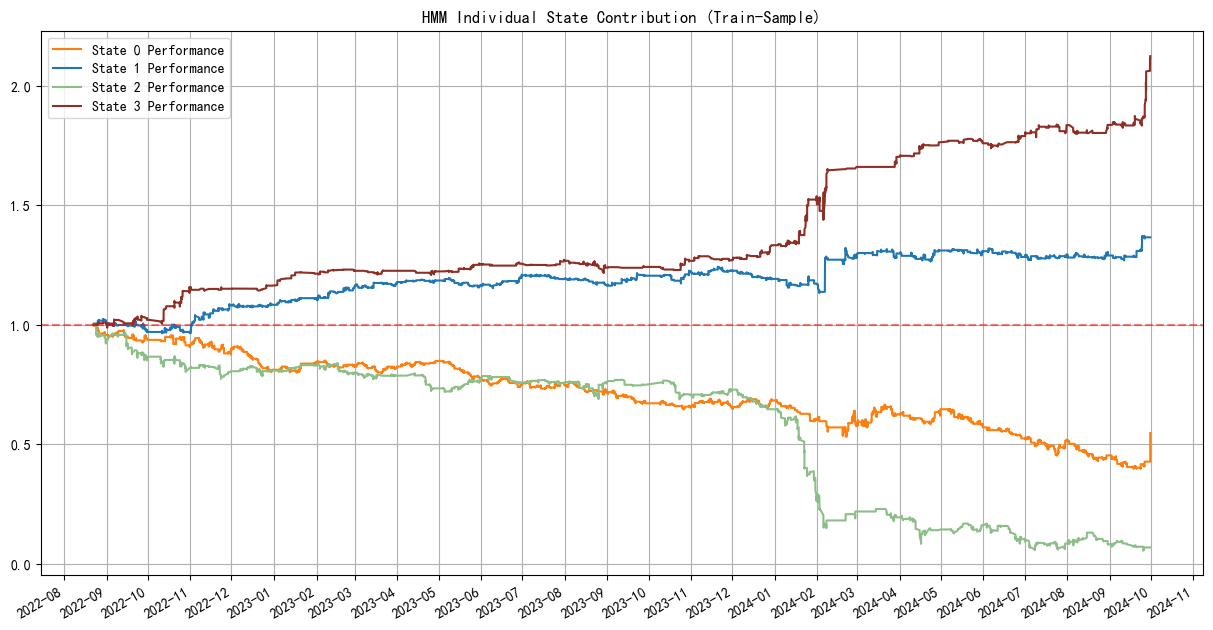

In [11]:
colors = ['#ff7f0e', '#1f77b4', "#8CBF87", "#8D2F25", "#909291", "#4E1945", "#B7B7Eb"]
plt.figure(figsize=(15, 8))
for i in range(model.n_components):
    df_train_sample = df_train_plot.copy()
    net = df_train_sample['pct'].astype(float).values
    signal = (df_train_sample['state'] == i).astype(float).values
    # 计算策略收益序列
    net_values, _ = cal_net_values(signal, net)
    plot_dates = df_train_sample.index
    plt.plot(plot_dates, net_values, color=colors[i], label=f'State {i} Performance')

plt.axhline(1, color='red', linestyle='--', alpha=0.5) #基准线
plt.title("HMM Individual State Contribution (Train-Sample)")
plt.legend()
plt.grid(True)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gcf().autofmt_xdate()
plt.show()

## 3.2 Out-of-Sample State Classification

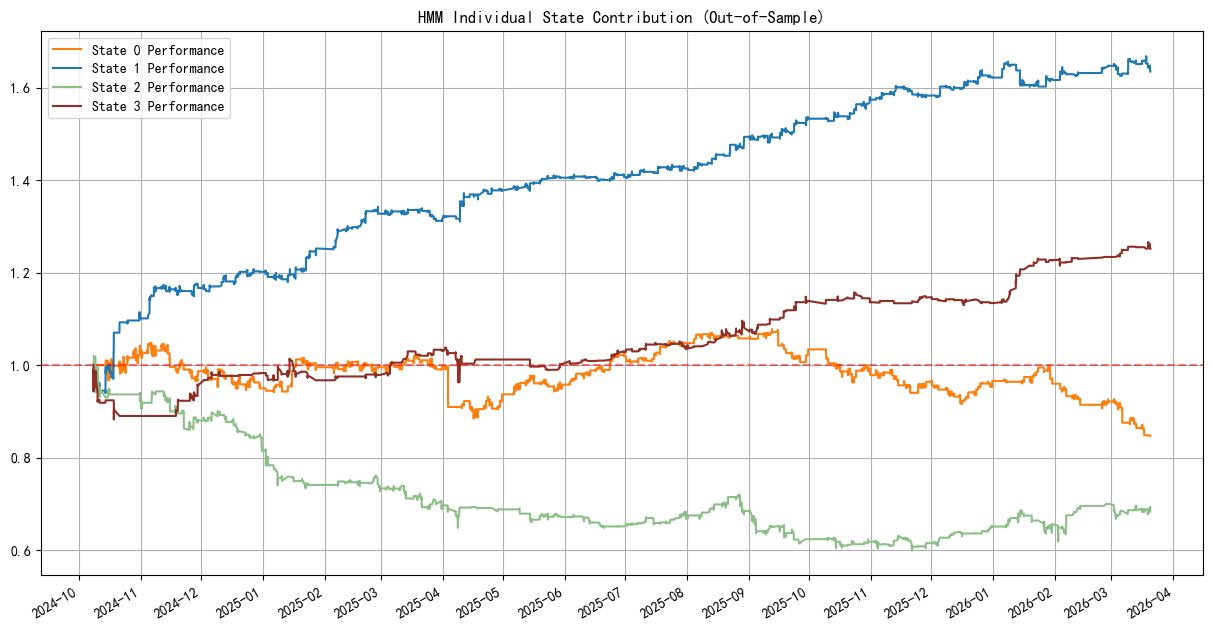

In [12]:
colors = ['#ff7f0e', '#1f77b4', "#8CBF87", "#8D2F25", "#909291", "#4E1945", "#B7B7Eb"]
plt.figure(figsize=(15, 8))
for i in range(model.n_components):
    df_test_sample = df_test_plot.copy()
    net = df_test_sample['pct'].astype(float).values
    signal = (df_test_sample['state'] == i).astype(float).values
    net_values, _ = cal_net_values(signal, net) 
    plot_dates = df_test_sample.index
    plt.plot(plot_dates, net_values, color=colors[i], label=f'State {i} Performance')

plt.axhline(1, color='red', linestyle='--', alpha=0.5) #基准线
plt.title("HMM Individual State Contribution (Out-of-Sample)")
plt.legend()
plt.grid(True)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gcf().autofmt_xdate()
plt.show()

## 3.3 Return Backtest Evaluation

### 3.3.1 Out-of-Sample Backtest

In [13]:
# 计算最大回撤
def calculate_mdd(cum_series):
    """
    计算净值曲线的最大回撤及其结束时间点
    """
    # 转换为 numpy 数组方便计算
    nav = np.array(cum_series)
    # 计算历史滚动最高点
    peaks = np.maximum.accumulate(nav)
    # 计算回撤序列 (当前值 / 历史最高值 - 1)
    drawdowns = (nav - peaks)
    # 找到最大回撤值（最小值）
    mdd_value = np.min(drawdowns)
    # 找到最大回撤发生的索引位置（即回撤结束/最低点的位置）
    mdd_idx = np.argmin(drawdowns)
    
    return mdd_value, mdd_idx

In [14]:
# 算上换手率
def cal_net_values(post:np.array,ret:np.array) -> np.array:
    '''计算净值序列
    pos: 仓位
    ret:未来1个周期的收益率'''
    fee = 0.0005 # 仓位每次变动的磨损
    position_changes = np.hstack((post[0],np.diff(post)))# 拼接初始仓位并记录此时的手续费，后面的时间使用diff的
    ret_array = post*ret - abs(position_changes*fee)
    net_values = 1+(ret_array).cumsum()
    return net_values, ret_array  # 返回净值序列、收益率序列

In [15]:
# 夏普计算
def calculate_sharpe(strat_ret, rf=0, periods=252):
    '''
    strat_ret: 策略收益率序列
    rf: 无风险利率 (年化)（市场的年化收益率）
    periods: 年度交易周期数 
    '''
    # 计算超额收益 (Daily Excess Return)
    excess_ret = strat_ret - (rf / periods)
    
    # 计算均值和标准差
    mean_ret = np.mean(excess_ret)
    std_ret = np.std(excess_ret)
    
    # 计算原始夏普 (非年化)
    if std_ret == 0:
        return 0
    sharpe = mean_ret / std_ret
    
    # 年化处理
    annual_sharpe = sharpe * np.sqrt(periods)
    
    return annual_sharpe


3
【市场基准】最大回撤: -69.50% | 发生时间: 2024-02-05 10:30:00
【HMM策略】最大回撤: -15.72% | 发生时间: 2024-02-05 10:30:00


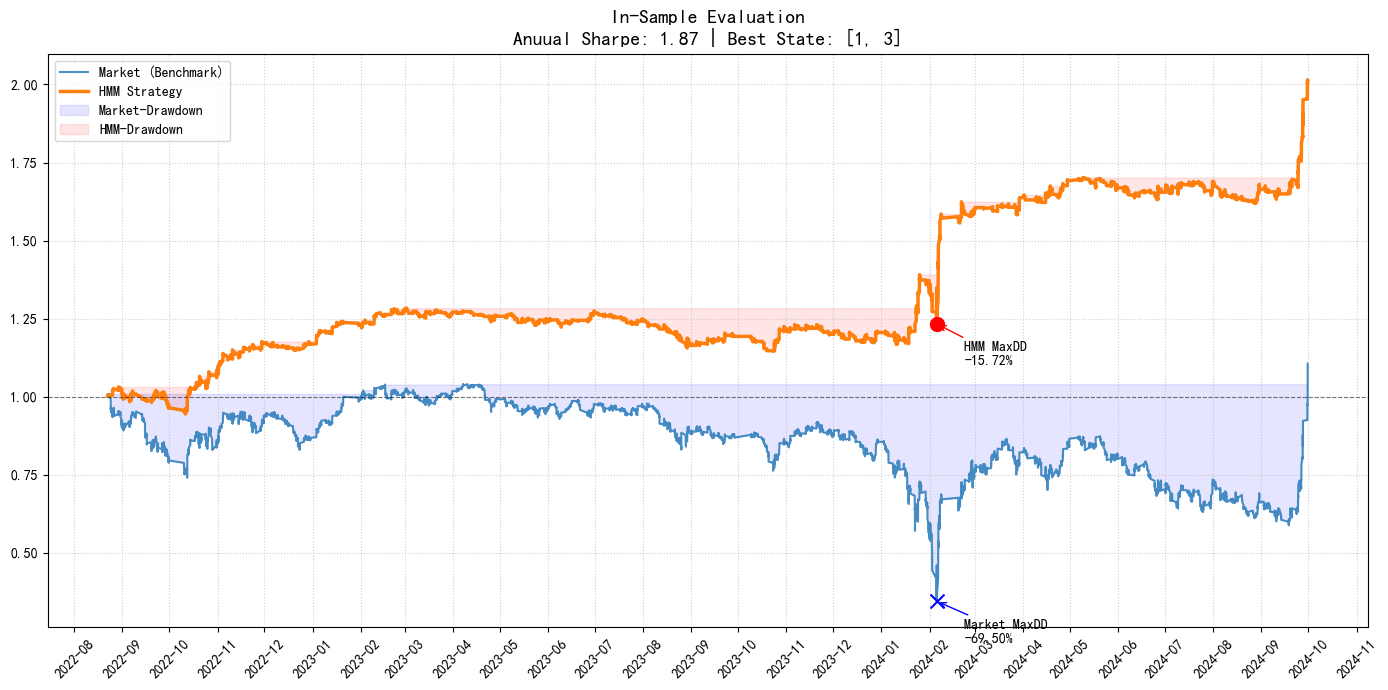

【市场基准】最大回撤: -25.03% | 发生时间: 2025-04-08 14:45:00
【HMM策略】最大回撤: -14.38% | 发生时间: 2024-10-14 10:00:00


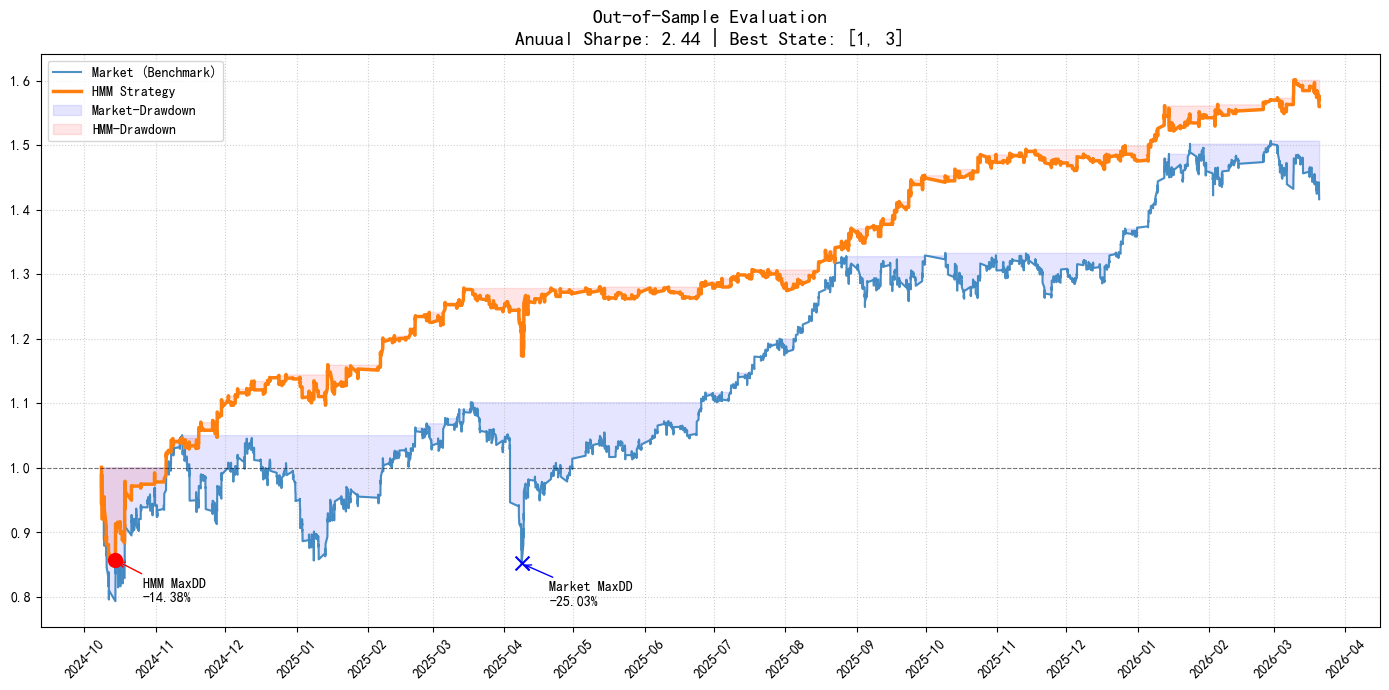

In [16]:
def plot_backtest(df_input, title, use_state):
    # 1. 深拷贝并预处理，确保无警告
    df = df_input.copy()
    df.index = pd.to_datetime(df.index)
    
    # T时刻的仓位取T+1时刻的收益率
    # 对不同状态取不同仓位
    pos_market = np.ones_like(df['state'].values)
    pos_array = df['state'].isin(use_state).astype(float).values # state
    
    # 计算策略收益序列
    res_values = df['pct'].astype(float).values

    net_values, _ = cal_net_values(pos_array, res_values)
    market_values, _ = cal_net_values(pos_market, res_values)
    
    # df['net_ret_array'] = net_ret_array
    # net_ret_date = df['net_ret_array'].groupby(df.index.date).apply(lambda x: np.prod(1 + x) - 1) # 复利计算收益率

    df['net_values'] = net_values
    net_ret_date = df['net_values'].groupby(df.index.date).last().diff()

    plot_dates = list(df.index)

    m_mdd_val, m_mdd_idx = calculate_mdd(market_values)
    s_mdd_val, s_mdd_idx = calculate_mdd(net_values)

    # 获取对应的日期（从 plot_dates 中提取）
    m_mdd_date = plot_dates[m_mdd_idx]
    s_mdd_date = plot_dates[s_mdd_idx]

    annual_sharpe = calculate_sharpe(net_ret_date)

    print(f"【市场基准】最大回撤: {m_mdd_val:.2%} | 发生时间: {m_mdd_date}")
    print(f"【HMM策略】最大回撤: {s_mdd_val:.2%} | 发生时间: {s_mdd_date}")

    plt.figure(figsize=(14, 7), dpi=100)
    
    # 使用你指定的蓝色和橙色
    plt.plot(plot_dates, market_values, color='#1f77b4', label='Market (Benchmark)', alpha=0.8)
    plt.plot(plot_dates, net_values, color='#ff7f0e', label='HMM Strategy', linewidth=2.5)
    
    # 绘制最大回撤区域（可选，更专业）
    market_peak = np.maximum.accumulate(market_values)
    strategy_peak = np.maximum.accumulate(net_values)
    plt.fill_between(plot_dates, market_values, market_peak, color='blue', alpha=0.1, label='Market-Drawdown')
    plt.fill_between(plot_dates, net_values, strategy_peak, color='red', alpha=0.1, label='HMM-Drawdown')

    # 起始点辅助线
    plt.axhline(1, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
    
    # 标题与统计信息
    plt.title(f"{title}\nAnuual Sharpe: {annual_sharpe:.2f} | Best State: {use_state}", fontsize=14)
    
    # 坐标轴优化
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.xticks(rotation=45)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper left')
    
    plt.tight_layout()
    plt.scatter(m_mdd_date, market_values[m_mdd_idx], color='blue', s=100, marker='x', 
            label=f'Market MaxDD: {m_mdd_val:.2%}', zorder=5)

    # 标记策略最大回撤点
    plt.scatter(s_mdd_date, net_values[s_mdd_idx], color='red', s=100, marker='o', 
                label=f'HMM MaxDD: {s_mdd_val:.2%}', zorder=5)
    plt.annotate(f'Market MaxDD\n{m_mdd_val:.2%}', 
                xy=(m_mdd_date, market_values[m_mdd_idx]), 
                xytext=(20, -30), textcoords='offset points',
                arrowprops=dict(arrowstyle='->', color='blue'))
    plt.annotate(f'HMM MaxDD\n{s_mdd_val:.2%}', 
                xy=(s_mdd_date, net_values[s_mdd_idx]), 
                xytext=(20, -30), textcoords='offset points',
                arrowprops=dict(arrowstyle='->', color='red'))
    plt.show()
# 状态总数
states = model.n_components
# 训练集确定best_state
best_state = df_train_plot.groupby('state')['close_log_ret_1p'].mean().idxmax()
print(best_state)
buy_state = [1,3]
plot_backtest(df_train_plot, "In-Sample Evaluation", buy_state)
plot_backtest(df_test_plot, "Out-of-Sample Evaluation", buy_state)

### 3.3.2 Full-Period Backtest

In [17]:
import pandas as pd
import numpy as np
from hmmlearn import hmm
import joblib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import mode
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号

# 数据准备+数据处理
df_min = pd.read_csv('../data/kline_im.csv')
df_min.set_index('DateTime', inplace=True)
df_min['vol_log_ret_1p'] = np.log(df_min['vol']) - np.log(df_min['vol'].shift(1))

df_min['vol_log_ret_5p'] = np.log(df_min['vol']) - np.log(df_min['vol'].shift(5))

df_min['close_log_ret_1p'] = np.log(df_min['close']) - np.log(df_min['close'].shift(1))

df_min['close_log_ret_5p'] = np.log(df_min['close']) - np.log(df_min['close'].shift(5))

df_min['intraday_range_log'] = np.log(df_min['high']) - np.log(df_min['low'])
# 删除前五行数据（滑窗）
df_min = df_min.drop(df_min.index[:5])
df_min.index = pd.to_datetime(df_min.index)
window = 336
features = ['vol_log_ret_1p','vol_log_ret_5p','close_log_ret_1p','close_log_ret_5p','intraday_range_log']
# 计算滚动均值和滚动标准差
rolling_mean = df_min[features].rolling(window=window).mean()
rolling_std = df_min[features].rolling(window=window).std()


# 执行滚动标准化
# 前 251 行会因为窗口不足产生 NaN
df_feature_rolling = (df_min[features] - rolling_mean) / rolling_std
df_train_norm = df_feature_rolling.loc[:'2024-09-30 15:00'].dropna()
df_test_norm = df_feature_rolling.dropna()
df_train_rolling = df_min.loc[df_train_norm.index]
df_test_rolling = df_min.loc[df_test_norm.index]


In [18]:
X_train = df_train_norm.values
X_test = df_test_norm.values
# 训练模型
model = hmm.GaussianHMM(n_components=4, 
                        covariance_type="full", 
                        n_iter=1000, 
                        random_state=42)

model.fit(X_train)
df_train_plot = df_train_rolling.copy() 
df_test_plot = df_test_rolling.copy()   
df_train_plot['state'] = model.predict(X_train)
df_test_plot['state'] = model.predict(X_test)
test_prob = model.predict_proba(X_test)

In [19]:
for i in range(model.n_components):
    df_test_plot[f'state_{i}_prob'] = test_prob[:, i]

## 3.4 Save Data

### 3.4.1 Save to im_model

In [20]:
# df_test = df_test_plot.copy()
# df_test.index = pd.to_datetime(df_test.index)

# # T时刻的仓位取T+1时刻的收益率
# # 对不同状态取不同仓位
# pos_market = np.ones_like(df_test['state'].values)
# pos_map = {3: 1.0, 2: -1.0, 1: 0.5, 0: -0.5}
# df_test['pos'] = df_test['state'].map(pos_map)
# pos_array = df_test['pos'].values
# # 计算策略收益序列
# res_values = df_test['pct'].astype(float).values
# print("res:", res_values)
# net_values, _ = cal_net_values(pos_array, res_values)
# market_values, _ = cal_net_values(pos_market, res_values)
# df_test["HMM-net"] = net_values
# df_test["market-net"] = market_values




In [21]:
# 确保两者的 index 都是 DateTime 类型
df_test = df_test_plot.copy()
df_test.index = pd.to_datetime(df_test.index)
df_im = pd.read_csv("../data/im_model.csv")
df_im.set_index('DateTime', inplace=True)
pos_map1 = {3: 1.0, 2: -1.0, 1: 1.0, 0: -1.0}
pos_map2 = {3: 1.0, 2: -1.0, 1: 0.5, 0: -0.5}
df_test['hmm_pos1'] = df_test['state'].map(pos_map1)
df_test['hmm_pos2'] = df_test['state'].map(pos_map2)
df_test.index = pd.to_datetime(df_test.index)
df_im.index = pd.to_datetime(df_im.index)

# how='left' 表示以 df1 为准，保留 df1 的所有时间戳
df_im = df_im.drop(columns=['hmm_pos1', 'hmm_pos2'], errors='ignore')
result = df_im.join(df_test[['hmm_pos1', 'hmm_pos2']], how='left')
result.to_csv("../data/im_model.csv")

### 3.4.2 Save to factor_values_norm_im

In [22]:
df_test = df_test_plot.copy()
df_test.index = pd.to_datetime(df_test.index)

# 确保两者的 index 都是 DateTime 类型
df_im = pd.read_csv("../data/factor_values_norm_im.csv")
df_im.set_index('DateTime', inplace=True)
df_im.index = pd.to_datetime(df_im.index)
df_im = df_im.replace([float('inf'), float('-inf')], 0)
df_im = df_im.fillna(0)
# how='left' 表示以 df1 为准，保留 df1 的所有时间戳
df_im = df_im.drop(columns=['pct', 'state','state_0_prob','state_1_prob','state_2_prob','state_3_prob'], errors='ignore')
result = df_im.join(df_test[['pct', 'state','state_0_prob','state_1_prob','state_2_prob','state_3_prob']], how='left')
result.to_csv("../data/factor_values_norm_im.csv")

# 4. Combinatorial Purged Cross-Validation (CPCV)

The reusable CPCV framework is imported from the local `cpcv.py` module. The feature-engineered frame from section 1 is passed into `run_cpcv`. CPCV splits the series into $N$ non-overlapping groups; each split holds out $k$ groups as the test set and trains on the rest, with independent purging / embargoing and per-block rolling standardisation, producing $\varphi = \binom{N-1}{k-1}$ complete backtest paths.

## 4.1 CPCV Input


In [23]:
# Reuse the feature-engineered frame from section 1 (no re-computation)
cpcv_df = df_min.reset_index()
cpcv_df.tail()


,DateTime,Unnamed: 0,day,open,high,low,close,vol,amount,twap,...,equal_kline_ratio,vwap_ema_1,vwap_ema_2,pct,slippage,vol_log_ret_1p,vol_log_ret_5p,close_log_ret_1p,close_log_ret_5p,intraday_range_log
14169,2026-03-20 13:45:00,11,2026/3/20,7660.0,7666.2,7642.0,7643.8,5447,8336630920,7652.946667,...,0.000000,1.529395e+06,1.530344e+06,-0.001465,1.308250e-07,0.074489,-0.393088,-0.002091,-0.008338,0.003162
14170,2026-03-20 14:00:00,12,2026/3/20,7643.8,7664.8,7625.6,7632.6,6613,10109080200,7643.773333,...,0.066667,1.526780e+06,1.528041e+06,-0.000524,1.310170e-07,0.193972,-0.676988,-0.001466,-0.016863,0.005127
14171,2026-03-20 14:15:00,13,2026/3/20,7633.0,7643.8,7619.4,7628.6,5162,7878171720,7631.746667,...,0.000000,1.525637e+06,1.526077e+06,-0.002779,1.310857e-07,-0.247713,-0.534450,-0.000524,-0.010769,0.003197
14172,2026-03-20 14:30:00,14,2026/3/20,7629.0,7639.0,7607.2,7607.4,6461,9848923520,7621.093333,...,0.066667,1.522494e+06,1.524336e+06,-0.006231,1.314510e-07,0.224460,-0.399826,-0.002783,-0.009758,0.004172
14173,2026-03-20 14:45:00,15,2026/3/20,7609.2,7622.0,7557.0,7560.0,13554,20564834800,7588.813333,...,0.000000,1.512081e+06,1.517114e+06,0.000000,1.322751e-07,0.740898,0.986106,-0.006250,-0.013115,0.008565


## 4.2 Run CPCV

In [24]:
from cpcv import run_cpcv, HMM_fit


In [25]:
params = {
    'n_groups': 6,
    'k_test_groups': 2,
    'window_size': 200,
    'purge_ticks': 0,
    'embargo_ticks': 0,
    'n_components': 4,
    'covariance_type': 'full',
    'tol': 1e-2,
    'n_iter': 1000,
    'random_state': 42,
    'feature_cols': [
        'vol_log_ret_1p',
        'vol_log_ret_5p',
        'close_log_ret_1p',
        'close_log_ret_5p',
        'intraday_range_log',
    ],
}

result = run_cpcv(
    df=cpcv_df,
    feature_cols=params['feature_cols'],
    model_factory=lambda: HMM_fit(
        n_components=params['n_components'],
        covariance_type=params['covariance_type'],
        n_iter=params['n_iter'],
        tol=params['tol'],
        random_state=params['random_state'],
    ),
    time_col='DateTime',
    prediction_col='state',
    n_groups=params['n_groups'],
    k_test_groups=params['k_test_groups'],
    window_size=params['window_size'],
    purge_ticks=params['purge_ticks'],
    embargo_ticks=params['embargo_ticks'],
)
backtest_paths = result['backtest_paths']


d:\Anaconda3\envs\RL\Lib\site-packages\numpy\_core\fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)
d:\Anaconda3\envs\RL\Lib\site-packages\numpy\_core\fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)
d:\Anaconda3\envs\RL\Lib\site-packages\numpy\_core\fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)
d:\Anaconda3\envs\RL\Lib\site-packages\numpy\_core\fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)
d:\Anaconda3\envs\RL\Lib\site-packages\numpy\_core\fromnumeric.py:54

In [26]:
def cal_state_net_values(state_signal, ret_array):
    state_signal = np.asarray(state_signal, dtype=float)
    ret_array = np.asarray(ret_array, dtype=float)
    state_ret_array = state_signal[:-1] * ret_array[1:]
    net_values = np.concatenate([[1.0], np.cumprod(1 + state_ret_array)])
    return net_values, state_ret_array


def plot_state_contribution(df_input, title, n_states=4, ret_col='pct'):
    colors = ['#ff7f0e', '#1f77b4', '#8CBF87', '#8D2F25', '#909291', '#4E1945', '#B7B7EB']
    df = df_input.copy()
    df.index = pd.to_datetime(df.index)

    plt.figure(figsize=(15, 8))
    for i in range(n_states):
        signal = (df['state'] == i).astype(float).values
        ret_array = df[ret_col].astype(float).values
        net_values, _ = cal_state_net_values(signal, ret_array)
        plt.plot(df.index, net_values, color=colors[i], label=f'State {i} Performance')

    plt.axhline(1, color='red', linestyle='--', alpha=0.5)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.gcf().autofmt_xdate()
    plt.show()


def plot_state_returns(df_input, title, n_states=4, ret_col='pct'):
    colors = ['#ff7f0e', '#1f77b4', '#8CBF87', '#8D2F25', '#909291', '#4E1945', '#B7B7EB']
    df = df_input.copy()
    df.index = pd.to_datetime(df.index)

    plt.figure(figsize=(15, 8))
    for i in range(n_states):
        signal = (df['state'] == i).astype(float).values
        ret_array = df[ret_col].astype(float).values
        _, state_ret_array = cal_state_net_values(signal, ret_array)
        plt.plot(df.index[1:], state_ret_array, color=colors[i], label=f'State {i} Return', linewidth=1)

    plt.axhline(0, color='red', linestyle='--', alpha=0.5)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.gcf().autofmt_xdate()
    plt.show()


## 4.3 CPCV State Contribution & Returns


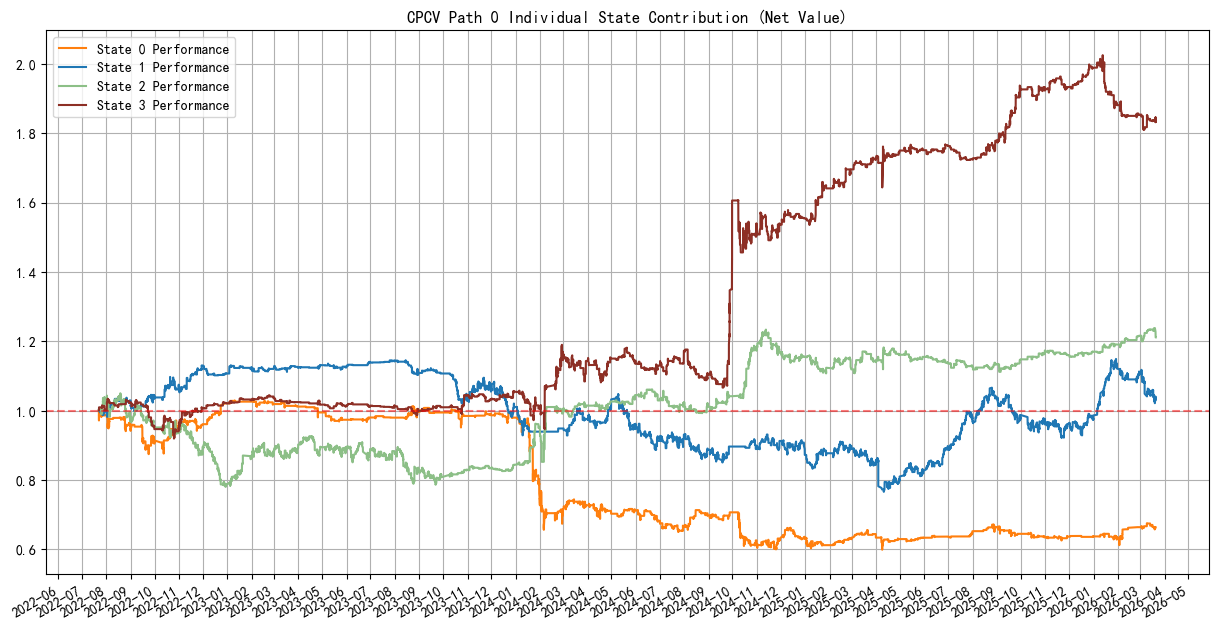

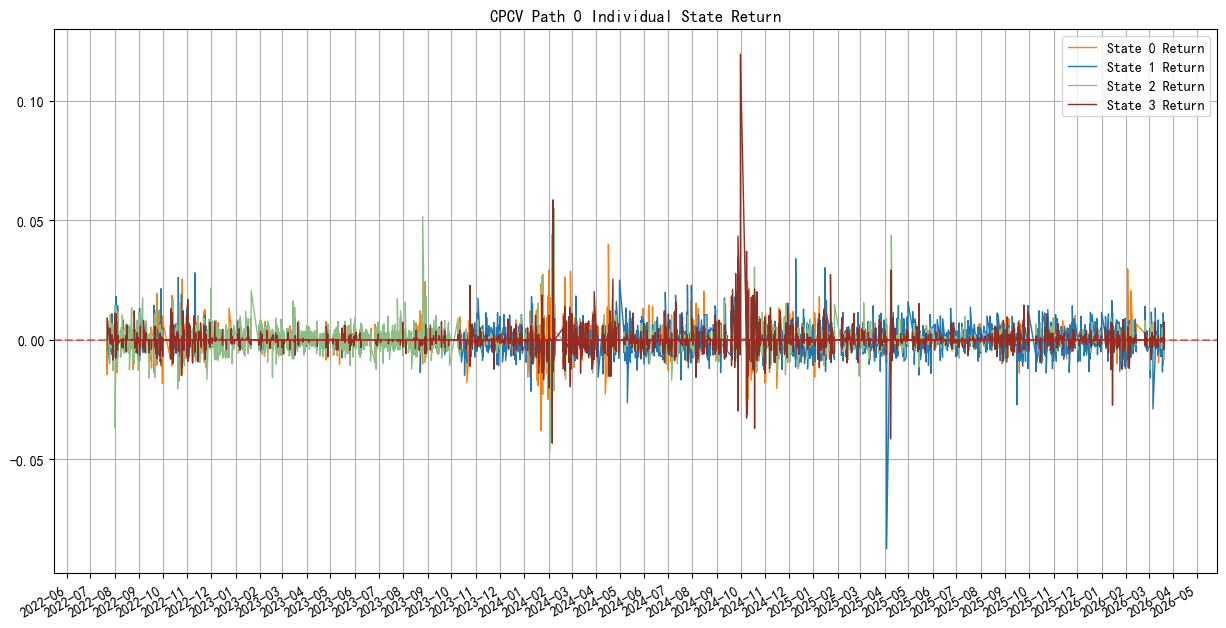

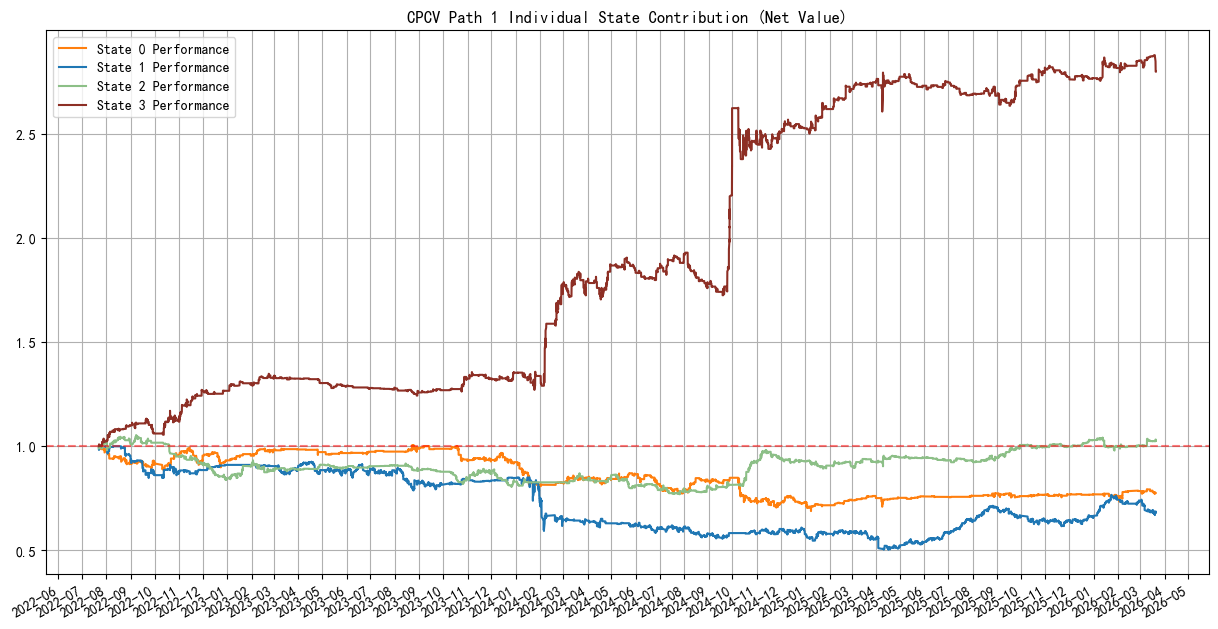

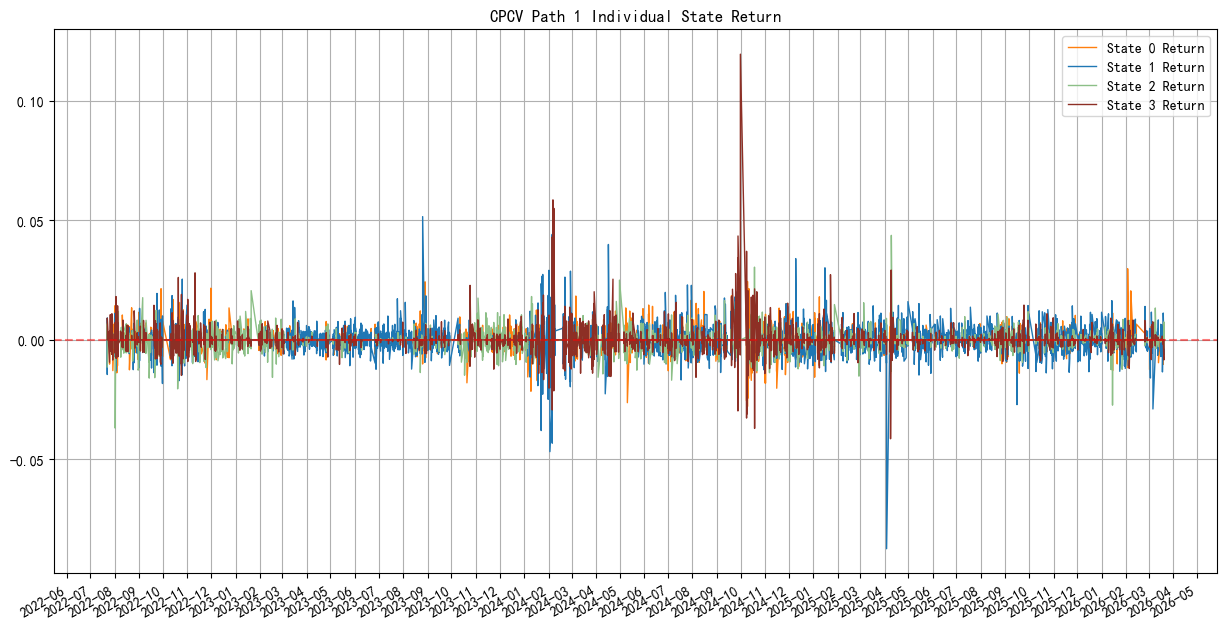

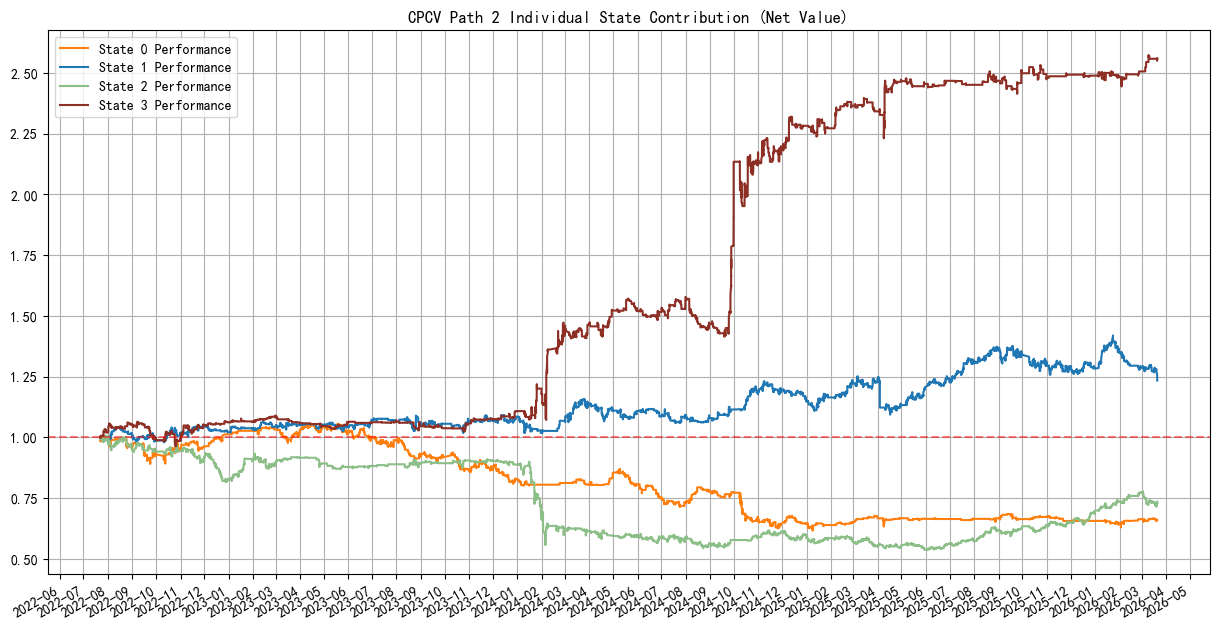

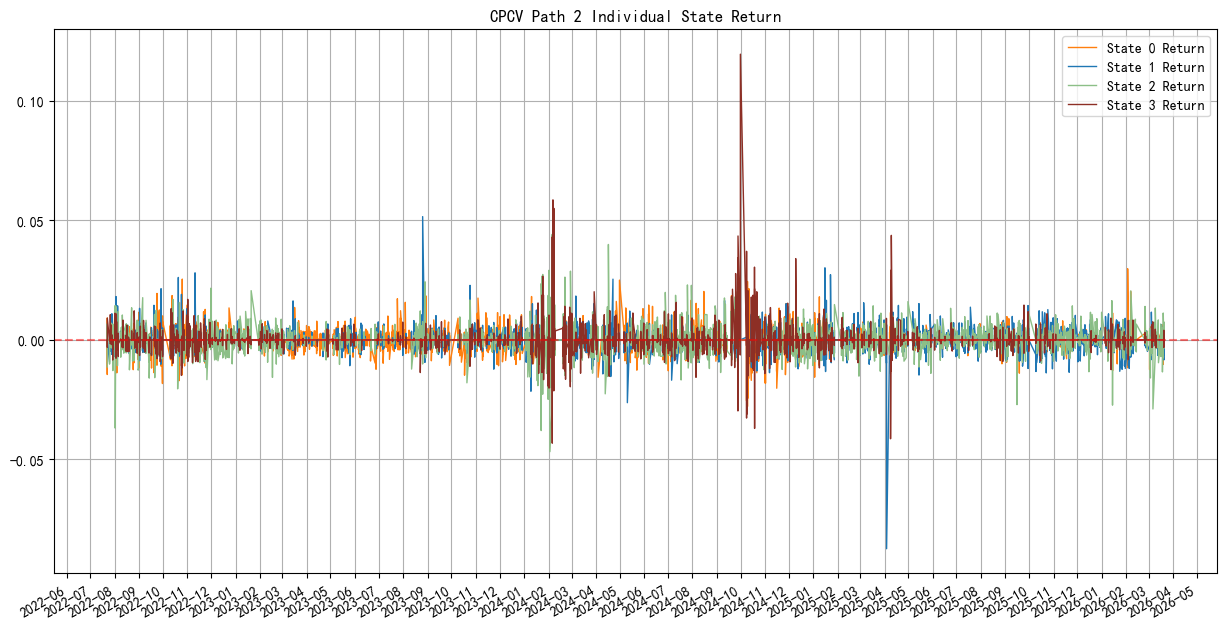

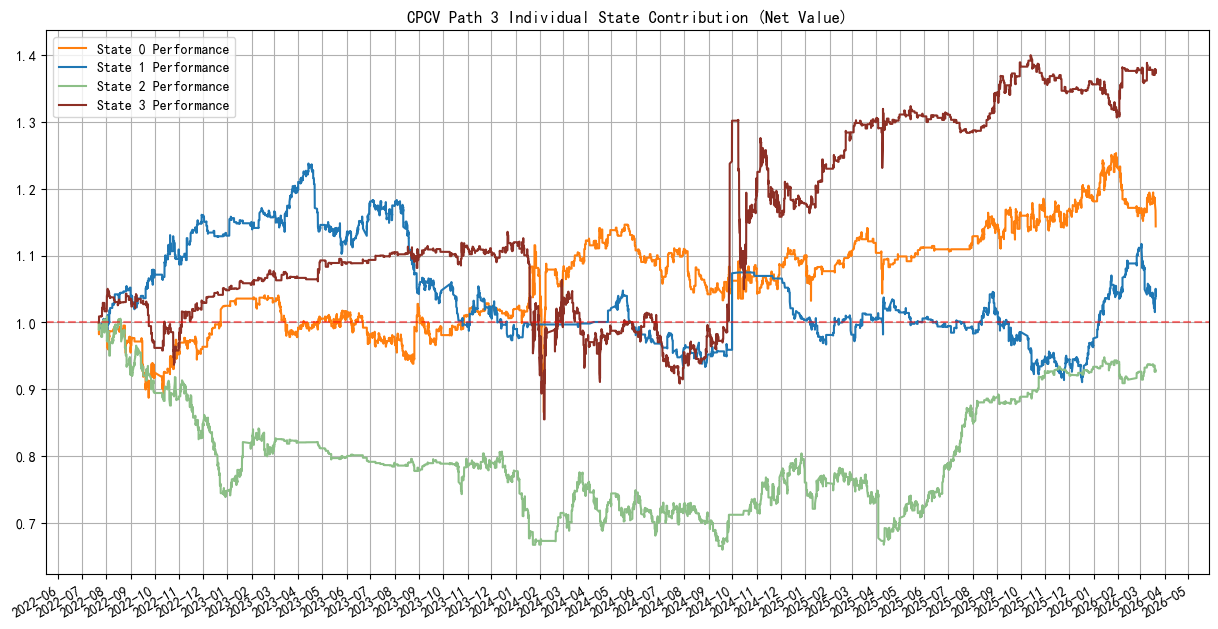

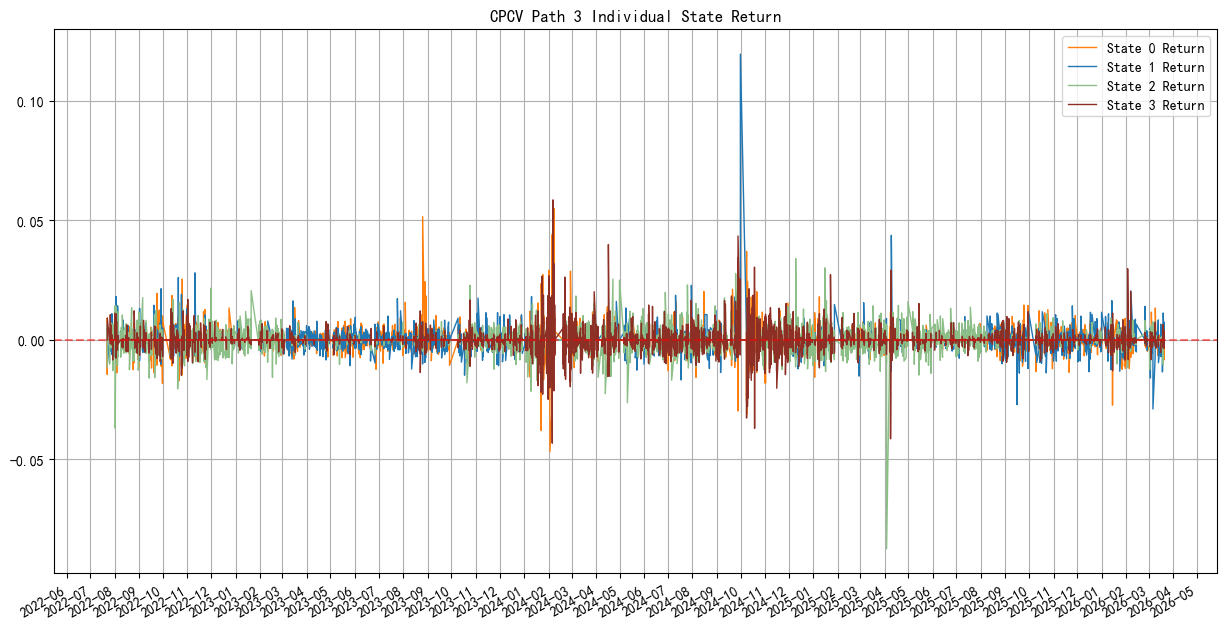

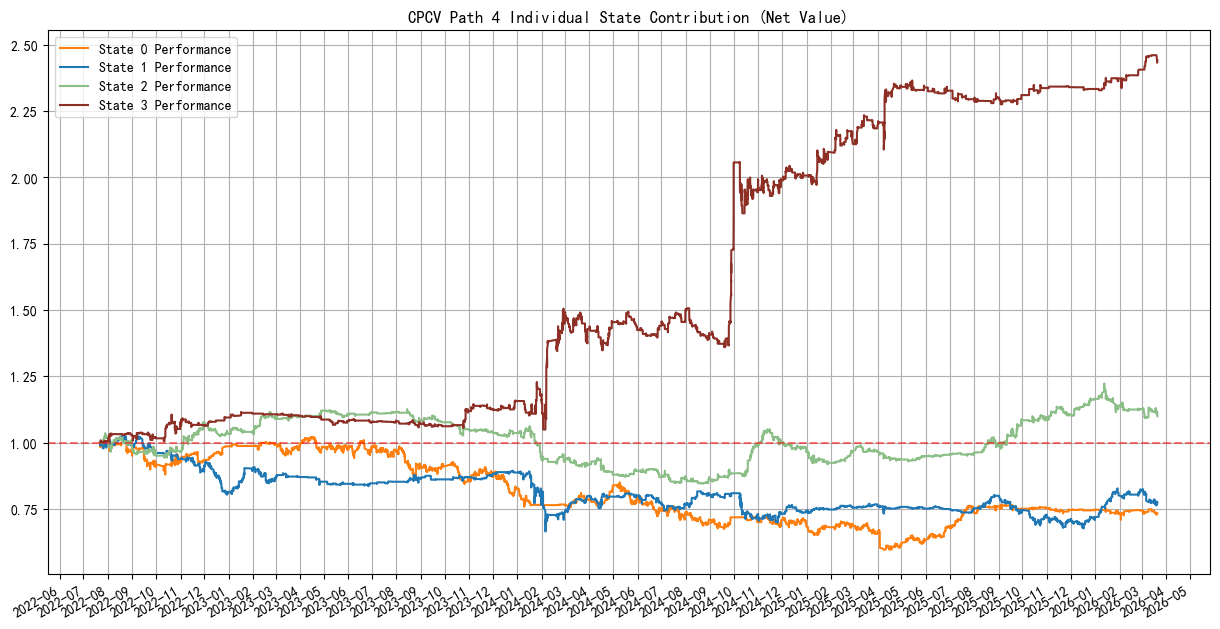

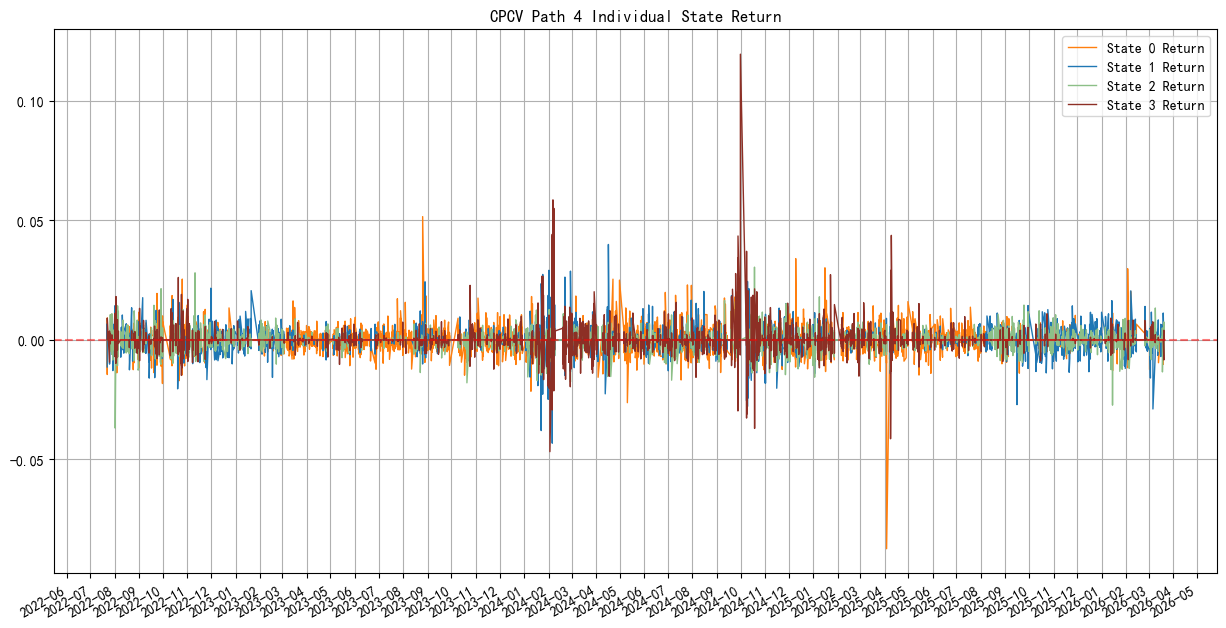

In [27]:
for path_id in range(result['phi']):
    df_path = backtest_paths[path_id].copy()
    plot_state_contribution(
        df_path,
        title=f'CPCV Path {path_id} Individual State Contribution (Net Value)',
        n_states=params['n_components'],
    )
    plot_state_returns(
        df_path,
        title=f'CPCV Path {path_id} Individual State Return',
        n_states=params['n_components'],
    )
